# Política de crédito: RAROC por faixa de score

Este notebook transforma a probabilidade do modelo (`submissao_case.csv`) em **decisões**: aprovar, aprovar com condições ajustadas ou recusar.

**O critério é o RAROC** (retorno ajustado ao risco sobre o capital), calculado para o primeiro ano de cada contrato:

$$\text{RAROC} = \frac{\text{juros} - \text{custo de captação} - \text{custo operacional} - \text{perda esperada}}{\text{capital alocado}}$$

- **Perda esperada** = PD × LGD × EAD, em que PD é a probabilidade de default, LGD é a fração do saldo perdida quando há default e EAD é o saldo devedor nesse momento.
- **Capital alocado** = 8% do saldo devedor médio no ano.
- Um pedido "se paga" quando o RAROC fica acima do **retorno mínimo** exigido pelo acionista.

**Três tipos de número aparecem aqui**, e a diferença importa:

| Tipo | O que é | Exemplos |
|---|---|---|
| **Dado** | Estimado das bases do case | Taxa de juros cobrada, momento do default, ordenação de risco do modelo |
| **Definição** | Fixado pelo projeto | Capital de 8% (Basileia) |
| **Premissa** | Não existe nas bases; valor proposto, a ser trocado pelo número real do banco | Custo de captação, custo operacional, retorno mínimo, LGD e nível de default dos cenários |


Toda a lógica está em `politica_credito.py`; aqui só instanciamos as classes.

**Hipótese que vale para todo o notebook:** mudar a taxa ou o limite **não muda a PD** do cliente. A base não tem variação de preço para medir esse efeito (seção 10).

Os valores monetários estão na unidade da base, em milhões.


| Alavanca na Política de Crédito | Ação Direta na Fórmula do RAROC | Efeito Teórico Projetado | Efeito Colateral Real (Trade-off de Mercado) |
| --- | --- | --- | --- |
| **Aumentar Taxas de Juros** | Aumenta a Receita (Numerador). | **Aumento rápido** | Causa seleção adversa (bons clientes fogem). Inadimplência dispara no longo prazo e o Capital exigido sobe, destruindo o RAROC. |
| **Melhorar Garantias** | Reduz a Perda Dado o Default (LGD) e a exigência de Capital Econômico (Denominador). | **Aumento sustentável** | Reduz risco sem encarecer crédito. O atrito é comercial: exige mais burocracia e tecnologia para travar garantias (ex: integração com maquininhas). |
| **Target de PD Conservador** | Aumenta a PD estatística e o Capital Econômico exigido. | **Queda severa** | Protege o balanço, mas pune clientes por pequenos atrasos (ignora taxa de cura). Trava a originação e estrangula o crescimento. |
| **Target de PD Tolerante** | Reduz a PD estatística e o Capital Econômico exigido na largada. | **Aumento ilusório** | Mascara a deterioração da carteira. Gera bônus no curto prazo, mas cria perdas irreversíveis e destruição de caixa no longo prazo. |
| **Investir em Data Science e IA (Novos Modelos)** | **Reduz drasticamente a Perda Esperada (EL)** e otimiza o Capital Econômico via melhor discriminação de risco. **Aumenta os Custos OpEx** na largada. | **Queda inicial, seguida de Alta Consistente** | **Curva em "J":** Alto custo inicial de folha e tecnologia (salários caros, compra de dados). Demora para dar retorno (*time-to-market* do modelo). Choque cultural entre crédito tradicional e área de dados. |

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from politica_credito import CalculadoraRAROC, CenarioRisco, HistoricoCredito, Politica, Premissas, montar_carteira

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
AZUL, LARANJA, AQUA, ROXO, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
PASTA_SAIDA = Path("outputs")
PASTA_SAIDA.mkdir(exist_ok=True)
MILHOES = 1e6
N_FAIXAS = 5  # quintis da PD: faixa 1 = menor risco, faixa N_FAIXAS = maior risco

## 1. O que o histórico permite estimar

Antes de assumir qualquer coisa, vemos o que os contratos aprovados do histórico revelam.

### 1.1 Taxa de juros

A coluna de taxa de juros está quase toda vazia. Mas os contratos parcelados têm crédito, parcela e prazo, e com os três dá para calcular a **taxa implícita**: a taxa mensal que faz as parcelas pagarem exatamente o crédito (Tabela Price).

Contratos parcelados aprovados: 105,224
Taxa atual (mediana dos Cash loans aprovados desde 2024): 2.54% ao mês = 35.2% ao ano


tipo_contrato,Cash loans,Consumer loans
ano,,
2017,4.13,5.44
2018,4.39,5.44
2019,5.04,5.67
2020,4.61,4.79
2021,3.36,3.52
2022,3.33,2.93
2023,3.33,2.85
2024,2.54,3.05
2025,2.79,3.09


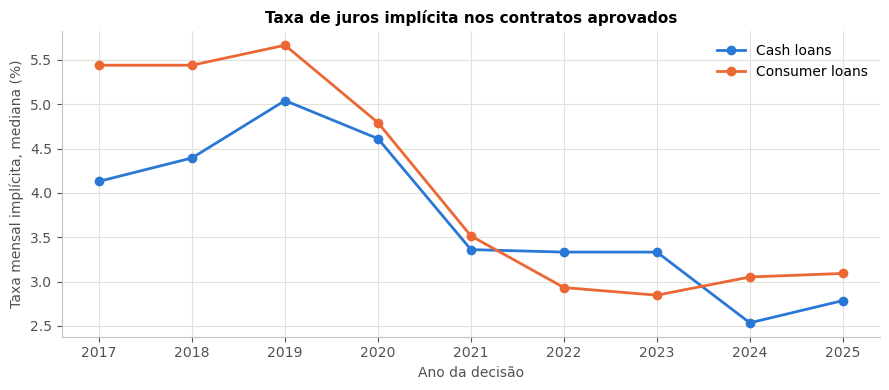

In [2]:
hist_emprestimos = pd.read_parquet("data/historico_emprestimos.parquet")
hist_parcelas = pd.read_parquet("data/historico_parcelas.parquet")
base_score = pd.read_parquet("data/processed/base_score.parquet")
# Cada cliente é observado até a data do próprio pedido, como na construção do target
historico = HistoricoCredito(hist_emprestimos, hist_parcelas, base_score.set_index("id_cliente")["data_referencia"])

taxas = historico.taxas_por_ano()
TAXA_ATUAL = historico.taxa_recente("Cash loans", desde="2024-01-01")
print(f"Contratos parcelados aprovados: {len(historico.contratos):,}")
print(f"Taxa atual (mediana dos Cash loans aprovados desde 2024): {TAXA_ATUAL:.2%} ao mês "
      f"= {(1 + TAXA_ATUAL) ** 12 - 1:.1%} ao ano")
display(taxas.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
for produto, cor in zip(taxas.columns, [AZUL, LARANJA]):
    ax.plot(taxas.index, taxas[produto], "o-", color=cor, linewidth=2, label=produto)
ax.set(xlabel="Ano da decisão", ylabel="Taxa mensal implícita, mediana (%)", title="Taxa de juros implícita nos contratos aprovados")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### 1.2 Momento do default e perda observada

Para os contratos que chegaram a 90 dias de atraso nos 12 primeiros meses, medimos:

- **quantas parcelas estavam pagas** no dia do evento (isso define o saldo exposto);
- **quanto do saldo nunca foi pago**. Um contrato encerrado foi quitado (verificado na EDA), então a perda dele é zero. Um contrato ainda aberto perde as parcelas do cronograma que não foram pagas.

A mesma conta é feita para 30 dias de atraso, que é o evento que o modelo prevê.

In [3]:
print("Contratos que atingiram 90 dias de atraso em 12 meses:")
display(historico.resumo_eventos(90).round(2))
print("Contratos que atingiram 30 dias de atraso em 12 meses:")
display(historico.resumo_eventos(30).round(2))

razao = historico.razao_default_sobre_atraso()
print("Dos que atingem 30 dias, quantos chegam a 90:")
display((razao * 100).round(1).to_frame("%"))

eventos = historico.eventos(90)
print(f"Total: {len(eventos)} contratos com 90 dias de atraso, {int((eventos['perda'] > 0).sum())} com alguma perda. "
      f"Perda sobre o saldo: {eventos['perda'].sum() / eventos['saldo'].sum():.1%}")

Contratos que atingiram 90 dias de atraso em 12 meses:


,contratos,parcelas_pagas_antes_mediana,saldo_sobre_credito_mediana,encerrados_pct,contratos_com_perda,perda_sobre_saldo_pct
tipo_contrato,,,,,,
Cash loans,77,8.0,0.62,80.52,13,32.38
Consumer loans,305,5.0,0.19,95.41,10,8.78


Contratos que atingiram 30 dias de atraso em 12 meses:


,contratos,parcelas_pagas_antes_mediana,saldo_sobre_credito_mediana,encerrados_pct,contratos_com_perda,perda_sobre_saldo_pct
tipo_contrato,,,,,,
Cash loans,390,5.0,0.78,88.97,38,10.71
Consumer loans,1477,5.0,0.32,97.49,21,1.59


Dos que atingem 30 dias, quantos chegam a 90:


,%
tipo_contrato,
Cash loans,19.7
Consumer loans,20.6
Revolving loans,16.2


Total: 382 contratos com 90 dias de atraso, 23 com alguma perda. Perda sobre o saldo: 26.9%


**Leitura.**

- **Taxa de juros.** A taxa implícita dos Cash loans caiu de 4–5% ao mês (2017–2020) para ~2,5–2,8% (2024–2025). A taxa atual usada na política é de **2,54% ao mês** (35% ao ano).
- **Momento do default.** Nos Cash loans que chegaram a 90 dias de atraso, a mediana é de **8 parcelas pagas** antes do evento, com 62% do crédito ainda em aberto. Nos Consumer loans, o saldo em aberto é bem menor (19%), porque os prazos são curtos.
- **A perda observada é mínima.** Dos 382 contratos parcelados que chegaram a 90 dias, 81% (Cash) e 95% (Consumer) foram encerrados depois, ou seja, quitados. **Só 23 contratos tiveram alguma perda.** A perda sobre o saldo foi de 32% em Cash loans e 9% em Consumer loans.
- **Um atraso de 30 dias raramente vira default:** só ~20% dos que atingem 30 dias chegam a 90.

Duas consequências para a política:

1. Com 23 contratos, não dá para estimar o LGD por produto com confiança. Os valores observados servem só de âncora.
2. A base só tem clientes que voltaram a pedir crédito, então quem deu prejuízo de verdade quase não aparece. Usar essa perda ao pé da letra faria o risco parecer irrelevante. Por isso, o nível de perda vem de cenários (seção 3).

## 2. Carteira e faixas de score

A carteira a decidir são os 40.000 pedidos da submissão, com a probabilidade entregue pelo modelo.

- **Faixas de score:** os pedidos são divididos em 5 grupos de mesmo tamanho (quintis) pela PD do modelo (faixa 1 = menor risco, faixa 5 = maior risco). Faixas relativas não mudam quando o modelo é recalibrado. Usamos 5 faixas, e não 10, porque o modelo foi validado com poucos maus (111 no teste): faixas mais finas teriam taxas de default muito ruidosas para sustentar uma decisão.
- **Prazo:** a submissão não traz prazo nem taxa. O prazo de cada pedido é deduzido do crédito e da parcela, **supondo que todos pagam a taxa atual**. É uma premissa necessária: sem ela não há como calcular juros.

In [4]:
submissao = pd.read_csv("submissao_case.csv")
carteira = montar_carteira(base_score, submissao, TAXA_ATUAL, n_faixas=N_FAIXAS)

perfil = carteira.groupby("faixa").agg(
    pedidos=("id_cliente", "size"),
    pd_modelo_pct=("pd_modelo", lambda x: x.mean() * 100),
    credito_medio=("valor_credito", "mean"),
    prazo_mediano=("prazo", "median"),
    sem_historico_pct=("hist_sem_historico", lambda x: x.mean() * 100),
    revolving_pct=("tipo_contrato", lambda x: x.eq("Revolving loans").mean() * 100),
)
display(perfil.round(2))
print(f"Crédito total pedido: {carteira['valor_credito'].sum() / MILHOES:,.0f} milhões")
print(f"Prazo implícito: mediana de {carteira['prazo'].median():.0f} meses; "
      f"{carteira['prazo'].eq(60).mean():.1%} dos pedidos ficam no teto de 60 meses")

,pedidos,pd_modelo_pct,credito_medio,prazo_mediano,sem_historico_pct,revolving_pct
faixa,,,,,,
1,8000,0.13,672026.40,30.0,0.00,0.65
2,8000,0.26,631923.62,29.0,0.04,1.79
3,8000,0.42,586356.03,28.0,1.29,4.85
4,8000,0.70,540336.99,28.0,5.60,13.04
5,8000,1.58,500655.30,28.0,18.68,22.19


Crédito total pedido: 23,450 milhões
Prazo implícito: mediana de 28 meses; 17.1% dos pedidos ficam no teto de 60 meses


**Leitura.**

- A PD média do modelo vai de 0,13% na faixa 1 a 1,58% na faixa 5
- **Os melhores clientes pedem mais crédito** 
- **Os clientes sem histórico se concentram na faixa 5** 
- **Os Revolving loans também se concentram nas faixas de maior risco** 
- **17% dos pedidos ficam no teto de 60 meses de prazo** 

## 3. Premissas e cenários de risco

### 3.1 Parâmetros econômicos

| Parâmetro | Valor | Tipo | Justificativa |
|---|---|---|---|
| Taxa de juros atual | ver célula abaixo | **Dado** | Mediana da taxa implícita dos Cash loans aprovados desde 2024 |
| Momento do default | ver célula abaixo | **Dado** | Mediana de parcelas pagas pelos Cash loans que chegaram a 90 dias |
| Capital | 8% do saldo médio | **Definição** | Requerimento mínimo de Basileia. Nota: os 8% incidem sobre o ativo ponderado pelo risco; com o peso de 75% usual no varejo, seriam 6% do saldo. Usamos 8% do saldo, a versão mais conservadora, e testamos 6% na seção 8 |
| Custo de captação | 1,0% ao mês (~12,7% ao ano) | **Premissa** | Ordem de grandeza da taxa básica de juros brasileira no início de 2025 (cerca de 13% ao ano) |
| Custo operacional | 4% ao ano do saldo médio | **Premissa** | Originação, atendimento e cobrança |
| Retorno mínimo | 20% ao ano, antes de impostos | **Premissa** | Retorno que o acionista exige sobre o capital |

### 3.2 Cenários de risco

A seção 1 mostrou que a perda observada na base é mínima, porque ela só contém clientes que voltaram a pedir crédito. Por isso, o **nível** de perda vem de três cenários. A **ordenação** dos clientes vem sempre do modelo: as chances de default de todos são multiplicadas pela mesma constante até a média da carteira bater o nível do cenário.

| Cenário | Default médio em 12 meses | LGD | Para que serve |
|---|---|---|---|
| **Observado** | O que a base mostra (PD do modelo × fração dos atrasos de 30 dias que chegam a 90) | Perda observada nos Cash loans | Mostra o que os dados dizem ao pé da letra |
| **Mercado** | 5% (**premissa**) | 60% em Cash loans, 75% em Revolving (**premissa**) | **Cenário base das decisões.** Nível típico de crédito pessoal sem garantia, que inclui os clientes que não voltaram |
| **Estresse** | 10% (**premissa**) | Igual ao de mercado | Testa a folga das decisões |

O LGD é maior em Revolving porque o limite rotativo não tem cronograma de amortização nem bem associado.

In [5]:
cash_default = eventos[eventos["tipo_contrato"] == "Cash loans"]
PARCELAS_ANTES_DO_DEFAULT = int(cash_default["parcelas_pagas_antes"].median())
LGD_OBSERVADA = float(cash_default["perda"].sum() / cash_default["saldo"].sum())

premissas = Premissas(
    taxa_juros_mensal=TAXA_ATUAL,
    parcelas_pagas_antes_do_default=PARCELAS_ANTES_DO_DEFAULT,
    custo_captacao_mensal=0.010,
    custo_operacional_anual=0.04,
    capital=0.08,
    retorno_minimo=0.20,
)
calculadora = CalculadoraRAROC(premissas)

default_observado = float((carteira["pd_modelo"] * carteira["tipo_contrato"].map(razao)).mean())
CENARIOS = [
    CenarioRisco("Observado", default_observado, {"Cash loans": LGD_OBSERVADA, "Revolving loans": LGD_OBSERVADA}),
    CenarioRisco("Mercado", 0.05, {"Cash loans": 0.60, "Revolving loans": 0.75}),
    CenarioRisco("Estresse", 0.10, {"Cash loans": 0.60, "Revolving loans": 0.75}),
]
carteiras = {c.nome: c.aplicar(carteira) for c in CENARIOS}

print(premissas)
display(pd.DataFrame([
    {
        "cenário": c.nome,
        "default médio %": c.default_medio * 100,
        "LGD Cash %": c.lgd["Cash loans"] * 100,
        "LGD Revolving %": c.lgd["Revolving loans"] * 100,
        "default faixa 1 %": carteiras[c.nome].loc[carteira["faixa"] == 1, "pd_default"].mean() * 100,
        "default última faixa %": carteiras[c.nome].loc[carteira["faixa"] == N_FAIXAS, "pd_default"].mean() * 100,
    }
    for c in CENARIOS
]).set_index("cenário").round(2))

Premissas(taxa_juros_mensal=0.025427063929461105, parcelas_pagas_antes_do_default=8, custo_captacao_mensal=0.01, custo_operacional_anual=0.04, capital=0.08, retorno_minimo=0.2)


,default médio %,LGD Cash %,LGD Revolving %,default faixa 1 %,default última faixa %
cenário,,,,,
Observado,0.12,32.38,32.38,0.02,0.31
Mercado,5.00,60.00,75.00,1.10,12.15
Estresse,10.00,60.00,75.00,2.40,23.01


**Leitura.**

- **Observado:** default médio de 0,12% ao ano e LGD de 32%. A perda esperada é praticamente zero.
- **Mercado:** com a média em 5%, o default vai de 1,1% na faixa 1 a ~12% na faixa 5.
- **Estresse:** com a média em 10%, vai de 2,4% a 23,0%.

Nos cenários de mercado e de estresse, a faixa 5 é cerca de 10 vezes mais arriscada que a faixa 1. Essa relação é a contribuição do modelo. O nível é a premissa.

## 4. RAROC na política atual

A política atual é o ponto de partida: **aprovar todos os pedidos com a mesma taxa**. Para cada faixa, calculamos o RAROC nos três cenários. A linha tracejada é o retorno mínimo.

,Observado,Mercado,Estresse
faixa,,,
1,181.3,172.4,161.8
2,181.2,163.2,142.2
3,181.0,152.0,119.2
4,180.8,133.6,82.9
5,180.0,84.9,-2.6
carteira,180.9,144.5,107.0


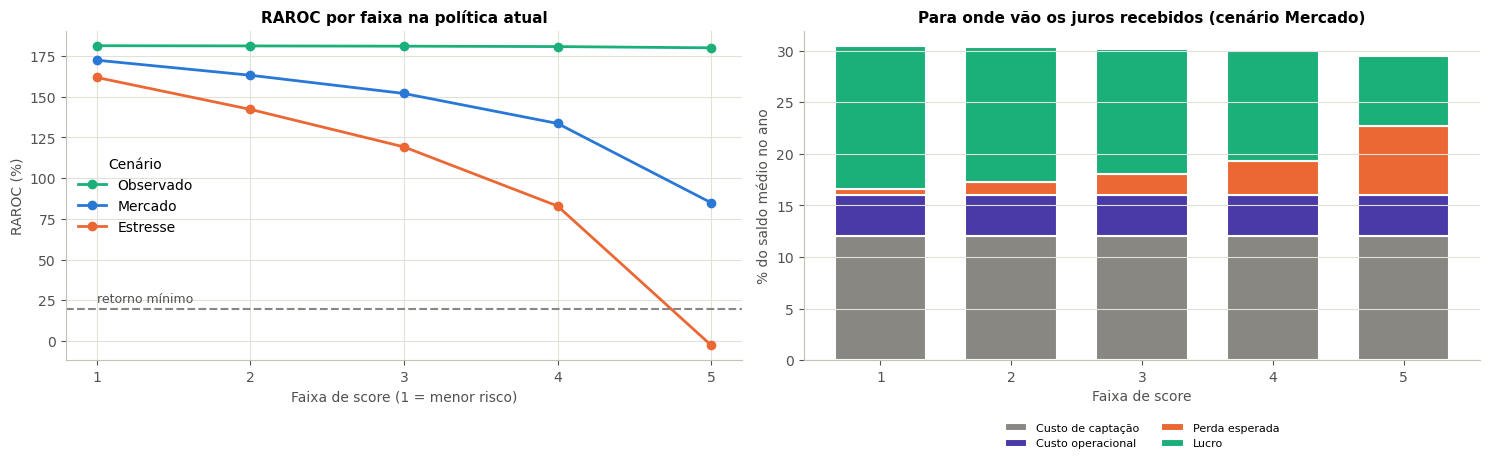

,custo_captacao,custo_operacional,perda_esperada,lucro,juros_recebidos
faixa,,,,,
1,12.0,4.0,0.62,13.79,30.41
2,12.0,4.0,1.26,13.05,30.31
3,12.0,4.0,2.03,12.16,30.19
4,12.0,4.0,3.31,10.69,29.99
5,12.0,4.0,6.69,6.79,29.48


In [6]:
por_faixa = {nome: calculadora.agregar(calculadora.calcular(c), por=c["faixa"]) for nome, c in carteiras.items()}
raroc_faixa = pd.DataFrame({nome: t["raroc_%"] for nome, t in por_faixa.items()})
raroc_faixa.loc["carteira"] = {nome: calculadora.raroc(c) * 100 for nome, c in carteiras.items()}
display(raroc_faixa.round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for nome, cor in zip(carteiras, [AQUA, AZUL, LARANJA]):
    axes[0].plot(range(1, N_FAIXAS + 1), raroc_faixa.loc[range(1, N_FAIXAS + 1), nome], "o-", color=cor, linewidth=2, label=nome)
axes[0].axhline(premissas.retorno_minimo * 100, color=CINZA, linestyle="--", linewidth=1.5)
axes[0].text(1, premissas.retorno_minimo * 100 + 4, "retorno mínimo", color="#52514e", fontsize=9)
axes[0].set_xticks(range(1, N_FAIXAS + 1))
axes[0].set(xlabel="Faixa de score (1 = menor risco)", ylabel="RAROC (%)", title="RAROC por faixa na política atual")
axes[0].legend(frameon=False, title="Cenário")

mercado = por_faixa["Mercado"]
partes = mercado[["custo_captacao", "custo_operacional", "perda_esperada", "lucro"]].div(mercado["saldo_medio"], axis=0) * 100
base = np.zeros(len(partes))
for coluna, rotulo, cor in zip(partes.columns, ["Custo de captação", "Custo operacional", "Perda esperada", "Lucro"], [CINZA, ROXO, LARANJA, AQUA]):
    axes[1].bar(partes.index, partes[coluna], bottom=base, color=cor, label=rotulo, width=0.7, edgecolor="white", linewidth=1.5)
    base += partes[coluna].to_numpy()
axes[1].set_xticks(range(1, N_FAIXAS + 1))
axes[1].set(xlabel="Faixa de score", ylabel="% do saldo médio no ano", title="Para onde vão os juros recebidos (cenário Mercado)")
axes[1].legend(frameon=False, ncols=2, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16))
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
display(partes.assign(juros_recebidos=partes.sum(axis=1)).round(2))

**Leitura.**

- **Observado: ~181% em todas as faixas.** A diferença entre a faixa 1 e a faixa 5 é de 1,3 ponto. Com a perda que a base mostra, o modelo não mudaria nenhuma decisão.
- **Mercado:** o RAROC cai de 172% na faixa 1 para 85% na faixa 5, e o da carteira é de 144,5%. Todas as faixas ficam muito acima do mínimo de 20%.
- **Estresse:** de 162% a **−3% na faixa 5**, a única que fica abaixo do mínimo. A carteira rende 107%.

**Por que todas as faixas rendem tanto?** O gráfico da direita mostra para onde vão os juros recebidos, que somam ~30% do saldo médio ao ano:

- captação: 12%;
- custo operacional: 4%;
- perda esperada: de 0,6% (faixa 1) a 6,7% (faixa 5);
- lucro: de 13,8% a 6,8%.

A margem antes da perda é de ~14% do saldo, contra um capital de 8%. Com uma margem dessa largura, a perda precisa ser muito alta para uma faixa deixar de se pagar. É por isso que o risco só passa a decidir na pior faixa e sob estresse.

## 5. Alavanca 1: corte de aprovação

O corte define até qual faixa o banco aprova. Há uma armadilha aqui: **o RAROC médio da carteira sempre sobe quando se corta a pior faixa**, porque sobra só o que rende mais. Levado ao limite, isso mandaria aprovar apenas a faixa 1.

O critério correto é o **RAROC marginal**: aprovar uma faixa enquanto ela, sozinha, pagar o retorno mínimo. Isso equivale a maximizar o **lucro econômico**, que é o lucro menos o custo do capital (retorno mínimo × capital alocado).

Cenário Mercado — aprovando da faixa 1 até a faixa da linha (lucro econômico em milhões):


,aprovacao_%,raroc_da_faixa_%,raroc_da_carteira_aprovada_%,lucro_economico_da_faixa,lucro_economico_acumulado
faixa,,,,,
1,20.0,172.4,172.4,575.8,575.8
2,40.0,163.2,168.0,505.4,1081.1
3,60.0,152.0,163.0,428.3,1509.4
4,80.0,133.6,156.6,336.5,1845.9
5,100.0,84.9,144.5,178.0,2023.8


Cenário Estresse — aprovando da faixa 1 até a faixa da linha (lucro econômico em milhões):


,aprovacao_%,raroc_da_faixa_%,raroc_da_carteira_aprovada_%,lucro_economico_da_faixa,lucro_economico_acumulado
faixa,,,,,
1,20.0,161.8,161.8,535.8,535.8
2,40.0,142.2,152.4,431.4,967.3
3,60.0,119.2,142.2,321.9,1289.1
4,80.0,82.9,129.2,186.4,1475.5
5,100.0,-2.6,107.0,-61.9,1413.6


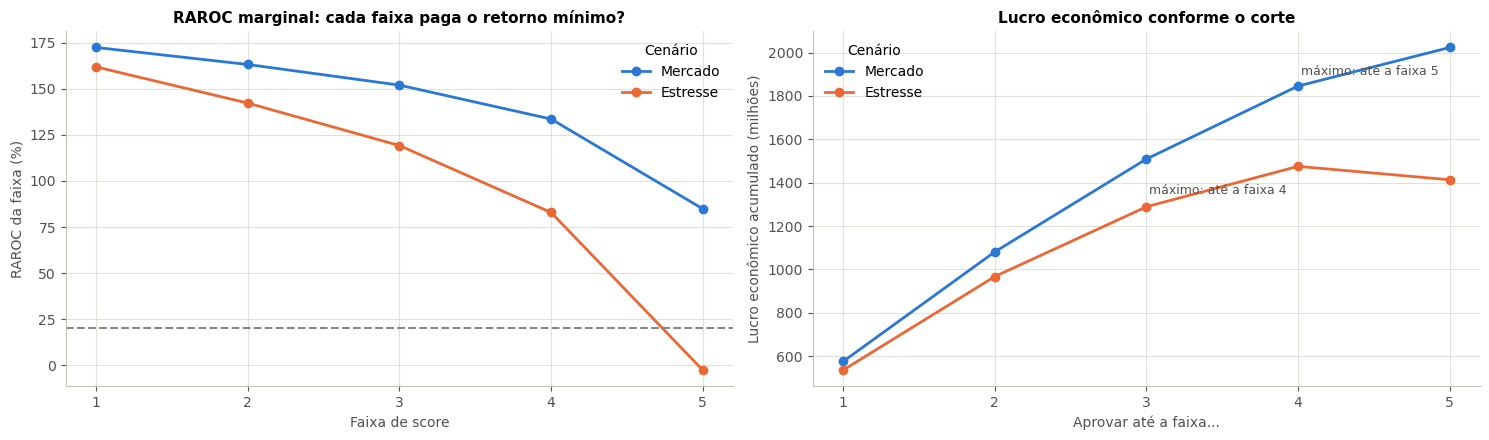

In [7]:
def curva_de_corte(tabela):
    acumulado = tabela[["pedidos", "lucro", "capital", "lucro_economico"]].cumsum()
    return pd.DataFrame({
        "aprovacao_%": acumulado["pedidos"] / tabela["pedidos"].sum() * 100,
        "raroc_da_faixa_%": tabela["raroc_%"],
        "raroc_da_carteira_aprovada_%": acumulado["lucro"] / acumulado["capital"] * 100,
        "lucro_economico_da_faixa": tabela["lucro_economico"] / MILHOES,
        "lucro_economico_acumulado": acumulado["lucro_economico"] / MILHOES,
    })

cortes = {nome: curva_de_corte(por_faixa[nome]) for nome in ["Mercado", "Estresse"]}
for nome, tabela in cortes.items():
    print(f"Cenário {nome} — aprovando da faixa 1 até a faixa da linha (lucro econômico em milhões):")
    display(tabela.round(1))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for (nome, tabela), cor in zip(cortes.items(), [AZUL, LARANJA]):
    axes[0].plot(tabela.index, tabela["raroc_da_faixa_%"], "o-", color=cor, linewidth=2, label=nome)
    axes[1].plot(tabela.index, tabela["lucro_economico_acumulado"], "o-", color=cor, linewidth=2, label=nome)
    melhor = tabela["lucro_economico_acumulado"].idxmax()
    axes[1].annotate(f"máximo: até a faixa {melhor}", (melhor, tabela["lucro_economico_acumulado"].max()),
                     xytext=(-8, -20), textcoords="offset points", ha="right", color="#52514e", fontsize=9)
axes[0].axhline(premissas.retorno_minimo * 100, color=CINZA, linestyle="--", linewidth=1.5)
axes[0].set(xlabel="Faixa de score", ylabel="RAROC da faixa (%)", title="RAROC marginal: cada faixa paga o retorno mínimo?")
axes[1].set(xlabel="Aprovar até a faixa...", ylabel="Lucro econômico acumulado (milhões)", title="Lucro econômico conforme o corte")
for ax in axes:
    ax.set_xticks(range(1, N_FAIXAS + 1))
    ax.legend(frameon=False, title="Cenário")
plt.tight_layout()
plt.show()


- **O ganho de recusar é menor que o custo:** 62 milhões em ~1.475 no estresse, contra uma perda de 178 milhões no cenário de mercado.

Recusar 20% dos clientes para evitar uma perda que só aparece no estresse não é a melhor resposta. A próxima seção mostra que um ajuste de preço resolve.

## 6. Alavanca 2: taxa de juros

Duas perguntas:

1. **Qual a menor taxa que cada faixa suporta?** É a taxa em que o RAROC da faixa fica exatamente no retorno mínimo. Abaixo dela, a faixa destrói valor. A diferença entre faixas é o **preço do risco**.
2. **Quanto o RAROC da carteira muda com a taxa?**

Taxa atual: 2.54% ao mês


,Observado,Mercado,Estresse,folga no Mercado (p.p.)
faixa,,,,
1,1.47,1.52,1.59,1.02
2,1.47,1.58,1.71,0.96
3,1.47,1.65,1.86,0.89
4,1.47,1.77,2.10,0.77
5,1.48,2.09,2.71,0.45


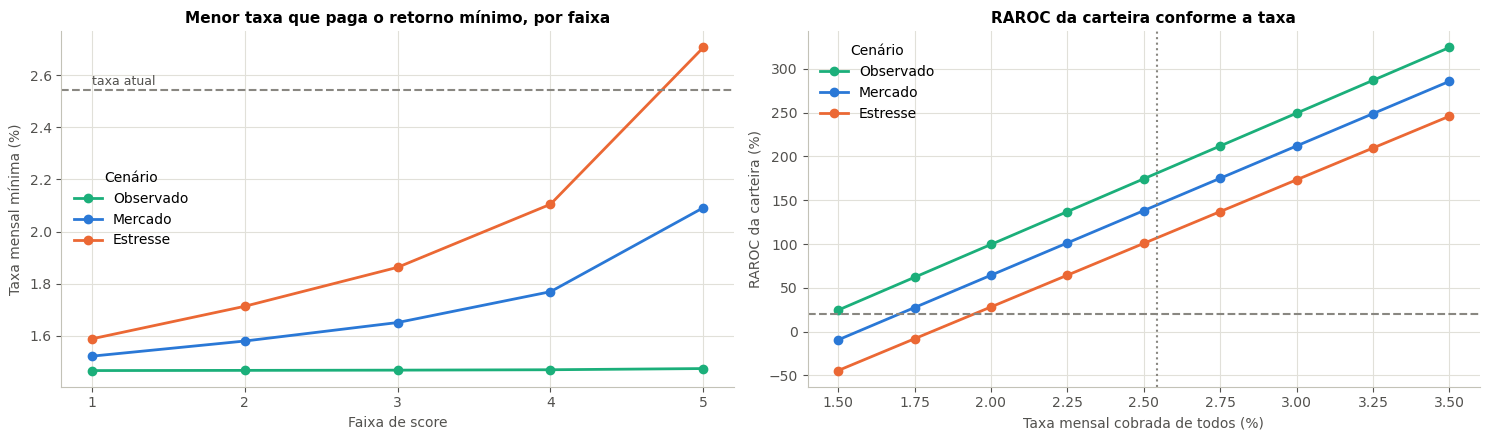

In [8]:
decisao = calculadora.tabela_decisao(carteiras["Mercado"], carteiras["Estresse"])
taxas_minimas = pd.DataFrame({
    "Observado": [calculadora.taxa_minima(carteiras["Observado"][carteira["faixa"] == f]) * 100 for f in range(1, N_FAIXAS + 1)],
    "Mercado": decisao["taxa_minima_base_%"].to_numpy(),
    "Estresse": decisao["taxa_minima_estresse_%"].to_numpy(),
}, index=pd.RangeIndex(1, N_FAIXAS + 1, name="faixa"))
taxas_minimas["folga no Mercado (p.p.)"] = TAXA_ATUAL * 100 - taxas_minimas["Mercado"]
print(f"Taxa atual: {TAXA_ATUAL:.2%} ao mês")
display(taxas_minimas.round(2))

grade = np.arange(0.015, 0.0351, 0.0025)
raroc_por_taxa = pd.DataFrame({nome: [calculadora.raroc(c, taxa=t) * 100 for t in grade] for nome, c in carteiras.items()},
                              index=grade * 100)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for nome, cor in zip(["Observado", "Mercado", "Estresse"], [AQUA, AZUL, LARANJA]):
    axes[0].plot(taxas_minimas.index, taxas_minimas[nome], "o-", color=cor, linewidth=2, label=nome)
    axes[1].plot(raroc_por_taxa.index, raroc_por_taxa[nome], "o-", color=cor, linewidth=2, label=nome)
axes[0].axhline(TAXA_ATUAL * 100, color=CINZA, linestyle="--", linewidth=1.5)
axes[0].text(1, TAXA_ATUAL * 100 + 0.02, "taxa atual", color="#52514e", fontsize=9)
axes[0].set_xticks(range(1, N_FAIXAS + 1))
axes[0].set(xlabel="Faixa de score", ylabel="Taxa mensal mínima (%)", title="Menor taxa que paga o retorno mínimo, por faixa")
axes[1].axhline(premissas.retorno_minimo * 100, color=CINZA, linestyle="--", linewidth=1.5)
axes[1].axvline(TAXA_ATUAL * 100, color=CINZA, linestyle=":", linewidth=1.5)
axes[1].set(xlabel="Taxa mensal cobrada de todos (%)", ylabel="RAROC da carteira (%)", title="RAROC da carteira conforme a taxa")
for ax in axes:
    ax.legend(frameon=False, title="Cenário")
plt.tight_layout()
plt.show()

- **A taxa é a alavanca mais forte.** No gráfico da direita, cada 0,25 ponto percentual ao mês vale ~37 pontos de RAROC da carteira. No cenário de mercado, uma taxa única abaixo de ~1,7% deixaria a carteira abaixo do retorno mínimo.

O ajuste de preço resolve o caso da faixa 5 sem recusar ninguém: a taxa que o estresse exige (2,71%) fica 0,16 ponto acima da atual (2,54%).

## 7. Alavanca 3: limite de crédito

Aprovar só uma parte do valor pedido. Testamos na faixa 5, a de maior risco.

In [9]:
pior_faixa = carteiras["Mercado"][carteira["faixa"] == N_FAIXAS]
linhas = []
for fator in [1.0, 0.7, 0.5]:
    total = calculadora.agregar(calculadora.calcular(pior_faixa.assign(fator_credito=fator))).iloc[0]
    linhas.append({"valor aprovado": f"{fator:.0%} do pedido", "crédito (milhões)": total["credito"] / MILHOES,
                   "RAROC %": total["raroc_%"], "perda esperada (milhões)": total["perda_esperada"] / MILHOES,
                   "capital (milhões)": total["capital"] / MILHOES, "lucro econômico (milhões)": total["lucro_economico"] / MILHOES})
display(pd.DataFrame(linhas).set_index("valor aprovado").round(1))

,crédito (milhões),RAROC %,perda esperada (milhões),capital (milhões),lucro econômico (milhões)
valor aprovado,,,,,
100% do pedido,4005.2,84.9,229.2,274.2,178.0
70% do pedido,2803.7,84.9,160.4,191.9,124.6
50% do pedido,2002.6,84.9,114.6,137.1,89.0


**Leitura.**

- **O RAROC não muda** (85% nos três casos). Lucro e capital caem na mesma proporção quando o valor aprovado cai.
- **O que muda é o tamanho da exposição:** aprovando 70% do pedido, a perda esperada cai de 229 para 160 milhões. O lucro econômico cai junto, de 178 para 125 milhões.

O limite, portanto, **não melhora o retorno**. Ele serve para controlar quanto o banco tem em jogo onde a estimativa de risco é menos confiável. É uma alavanca de prudência, com custo. (Se houvesse custo fixo por contrato, que não modelamos, reduzir o valor ainda pioraria o RAROC.)

## 8. Sensibilidade às premissas

As premissas da seção 3 não vêm dos dados, então é preciso saber quanto o resultado depende delas. Cada linha muda **uma** premissa por vez, no cenário Mercado, e mostra o RAROC da carteira inteira e o da pior faixa (a 5).

O custo operacional entra aqui, e não como alavanca de crédito: reduzi-lo é uma decisão de eficiência, não de concessão. Mas o efeito dele no RAROC é o que mostra quanto vale essa eficiência.

,valores,carteira: baixo,carteira: alto,pior faixa: baixo,pior faixa: alto
premissa,,,,,
Base,,144.5,144.5,84.9,84.9
Custo operacional,2% / 6% ao ano,169.5,119.5,109.9,59.9
Custo de captação,"0,8% / 1,2% ao mês",174.5,114.5,114.9,54.9
Capital,"6% / 10,5% do saldo",192.7,110.1,113.2,64.7
Parcelas pagas antes do default,4 / 11 parcelas,134.4,151.7,57.7,104.1
LGD (Cash / Revolving),45% / 60% e 75% / 90%,152.3,136.7,105.1,64.7


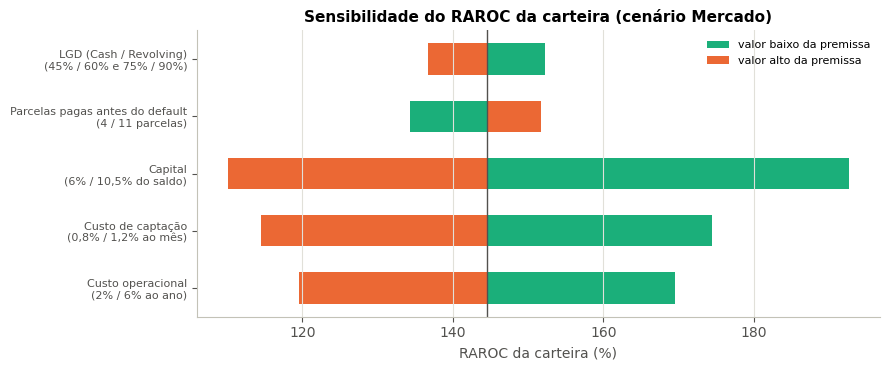

In [10]:
VARIACOES = [
    ("Custo operacional", "custo_operacional_anual", 0.02, 0.06, "2% / 6% ao ano"),
    ("Custo de captação", "custo_captacao_mensal", 0.008, 0.012, "0,8% / 1,2% ao mês"),
    ("Capital", "capital", 0.06, 0.105, "6% / 10,5% do saldo"),
    ("Parcelas pagas antes do default", "parcelas_pagas_antes_do_default", 4, 11, "4 / 11 parcelas"),
]
pior_faixa = carteiras["Mercado"][carteira["faixa"] == N_FAIXAS]
linhas = [{"premissa": "Base", "valores": "", "carteira: baixo": calculadora.raroc(carteiras["Mercado"]) * 100,
           "carteira: alto": calculadora.raroc(carteiras["Mercado"]) * 100,
           "pior faixa: baixo": calculadora.raroc(pior_faixa) * 100, "pior faixa: alto": calculadora.raroc(pior_faixa) * 100}]
for nome, parametro, baixo, alto, rotulo in VARIACOES:
    linhas.append({"premissa": nome, "valores": rotulo,
                   "carteira: baixo": calculadora.raroc(carteiras["Mercado"], **{parametro: baixo}) * 100,
                   "carteira: alto": calculadora.raroc(carteiras["Mercado"], **{parametro: alto}) * 100,
                   "pior faixa: baixo": calculadora.raroc(pior_faixa, **{parametro: baixo}) * 100,
                   "pior faixa: alto": calculadora.raroc(pior_faixa, **{parametro: alto}) * 100})
lgd_baixo = CenarioRisco("LGD baixo", 0.05, {"Cash loans": 0.45, "Revolving loans": 0.60}).aplicar(carteira)
lgd_alto = CenarioRisco("LGD alto", 0.05, {"Cash loans": 0.75, "Revolving loans": 0.90}).aplicar(carteira)
linhas.append({"premissa": "LGD (Cash / Revolving)", "valores": "45% / 60% e 75% / 90%",
               "carteira: baixo": calculadora.raroc(lgd_baixo) * 100, "carteira: alto": calculadora.raroc(lgd_alto) * 100,
               "pior faixa: baixo": calculadora.raroc(lgd_baixo[carteira["faixa"] == N_FAIXAS]) * 100,
               "pior faixa: alto": calculadora.raroc(lgd_alto[carteira["faixa"] == N_FAIXAS]) * 100})
sensibilidade = pd.DataFrame(linhas).set_index("premissa")
display(sensibilidade.round(1))

fig, ax = plt.subplots(figsize=(9, 3.8))
tabela = sensibilidade.iloc[1:]
base = sensibilidade.loc["Base", "carteira: baixo"]
y = np.arange(len(tabela))
ax.barh(y, tabela["carteira: baixo"] - base, left=base, color=AQUA, height=0.55, label="valor baixo da premissa")
ax.barh(y, tabela["carteira: alto"] - base, left=base, color=LARANJA, height=0.55, label="valor alto da premissa")
ax.axvline(base, color="#52514e", linewidth=1)
ax.set_yticks(y, [f"{i}\n({v})" for i, v in zip(tabela.index, tabela["valores"])], fontsize=8)
ax.set(xlabel="RAROC da carteira (%)", title="Sensibilidade do RAROC da carteira (cenário Mercado)")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Leitura.**

- **As premissas econômicas mexem mais no RAROC da carteira do que as de risco:**
  - capital: 192,7% com 6% do saldo, 110,1% com 10,5%;
  - custo de captação: 174,5% com 0,8% ao mês, 114,5% com 1,2%;
  - custo operacional: 169,5% com 2% ao ano, 119,5% com 6%.
- **Quanto vale reduzir o custo operacional:** cada ponto percentual a menos vale ~12,5 pontos de RAROC. É um ganho relevante, mas é uma decisão de eficiência, não de crédito.
- **As premissas de risco pesam na faixa 5.** Com LGD mais alto, o RAROC dela cai de 85% para 65%. Se o default acontecer mais cedo (4 parcelas pagas em vez de 8), cai para 58%.
- **Nenhuma variação isolada muda as decisões no cenário de mercado:** a carteira e a faixa 5 ficam sempre acima de 20%.

As decisões são robustas às premissas econômicas. O que as muda é o **nível de default** (cenário de estresse) e a **taxa de juros**.

## 9. Política proposta

**Regra de decisão por faixa.** O cenário Mercado decide e o Estresse testa a folga:

| Decisão | Condição |
|---|---|
| **Aprovar** | A faixa paga o retorno mínimo até no cenário de estresse |
| **Aprovar com condições** | Paga no cenário de mercado, mas não no de estresse |
| **Recusar** | Não paga o retorno mínimo nem no cenário de mercado |

**Condições ajustadas**, para as faixas em "aprovar com condições":

1. **Taxa:** no mínimo a taxa que paga o retorno mínimo no estresse (arredondada para cima em 0,1 ponto percentual).
2. **Limite:** 70% do valor pedido, para reduzir a perda em valor absoluto onde o risco é maior.

**Clientes sem histórico**, em qualquer faixa: limite de 70% do valor pedido. A PD deles tem mais incerteza, porque o modelo tem praticamente só o cadastro desses clientes (notebook de modelagem, seção 8).

Os limites são uma regra de **prudência**, não de RAROC: a seção 7 mostrou que reduzir o valor não muda o RAROC, só reduz a exposição. Para deixar esse custo visível, a tabela compara quatro políticas nos cenários Mercado e Estresse: a atual, a recusa da faixa 5, uma versão só com o ajuste de taxa e a proposta completa.

In [11]:
display(decisao.round(2))

com_condicoes = list(decisao.index[decisao["decisao"] == "Aprovar com condições"])
recusadas = tuple(decisao.index[decisao["decisao"] == "Recusar"])
ajuste_taxa = {int(f): float(max(0.0, np.ceil((decisao.loc[f, "taxa_minima_estresse_%"] / 100 - TAXA_ATUAL) * 1000) / 1000))
               for f in com_condicoes}
print("Faixas com condições:", [int(f) for f in com_condicoes],
      "| ajuste de taxa (p.p. ao mês):", {f: round(v * 100, 1) for f, v in ajuste_taxa.items()},
      "| faixas recusadas:", [int(f) for f in recusadas])

POLITICAS = [
    Politica("Atual: aprova todos, taxa única"),
    Politica(f"Corte: recusa a faixa {N_FAIXAS}", recusar_faixas=(N_FAIXAS,)),
    Politica("Só o ajuste de taxa", recusar_faixas=recusadas, ajuste_taxa=ajuste_taxa),
    Politica("Proposta: ajuste de taxa + limites", recusar_faixas=recusadas, ajuste_taxa=ajuste_taxa,
             fator_limite={f: 0.7 for f in com_condicoes}, fator_limite_sem_historico=0.7),
]
proposta = POLITICAS[-1]

def comparar(politicas, cenario):
    tabela = pd.DataFrame([calculadora.avaliar_politica(p, carteiras[cenario]) for p in politicas]).set_index("politica")
    tabela[["credito_concedido", "lucro", "capital", "lucro_economico"]] /= MILHOES
    return tabela.drop(columns="capital").rename(columns={
        "credito_concedido": "crédito (milhões)", "lucro": "lucro (milhões)", "lucro_economico": "lucro econômico (milhões)"})

for cenario in ["Mercado", "Estresse"]:
    print(f"Cenário {cenario}:")
    display(comparar(POLITICAS, cenario).round(1))

,pd_modelo_%,raroc_base_%,raroc_estresse_%,taxa_minima_base_%,taxa_minima_estresse_%,decisao
faixa,,,,,,
1,0.13,172.42,161.84,1.52,1.59,Aprovar
2,0.26,163.18,142.23,1.58,1.71,Aprovar
3,0.42,151.99,119.20,1.65,1.86,Aprovar
4,0.70,133.59,82.91,1.77,2.10,Aprovar
5,1.58,84.90,-2.56,2.09,2.71,Aprovar com condições


Faixas com condições: [5] | ajuste de taxa (p.p. ao mês): {5: 0.2} | faixas recusadas: []
Cenário Mercado:


,aprovacao_%,crédito (milhões),default_medio_%,perda_sobre_saldo_%,lucro (milhões),raroc_%,lucro econômico (milhões)
politica,,,,,,,
"Atual: aprova todos, taxa única",100.0,23450.4,5.0,2.6,2348.9,144.5,2023.8
Corte: recusa a faixa 5,80.0,19445.1,3.2,1.7,2116.1,156.6,1845.9
Só o ajuste de taxa,100.0,23450.4,5.0,2.6,2428.9,149.3,2103.6
Proposta: ajuste de taxa + limites,100.0,22131.1,5.0,2.3,2324.1,151.3,2016.9


Cenário Estresse:


,aprovacao_%,crédito (milhões),default_medio_%,perda_sobre_saldo_%,lucro (milhões),raroc_%,lucro econômico (milhões)
politica,,,,,,,
"Atual: aprova todos, taxa única",100.0,23450.4,10.0,5.1,1738.8,107.0,1413.6
Corte: recusa a faixa 5,80.0,19445.1,6.7,3.6,1745.8,129.2,1475.5
Só o ajuste de taxa,100.0,23450.4,10.0,5.2,1814.9,111.6,1489.5
Proposta: ajuste de taxa + limites,100.0,22131.1,10.0,4.7,1787.5,116.4,1480.4


,pedidos,credito_pedido,pd_modelo_pct,sem_historico,pedidos_%
decisao,,,,,
Aprovar,31446,19052.90,0.37,0,78.61
Aprovar com condições,8554,4397.48,1.52,2048,21.38


Decisão de cada pedido salva em outputs/politica_submissao.csv (40,000 linhas)


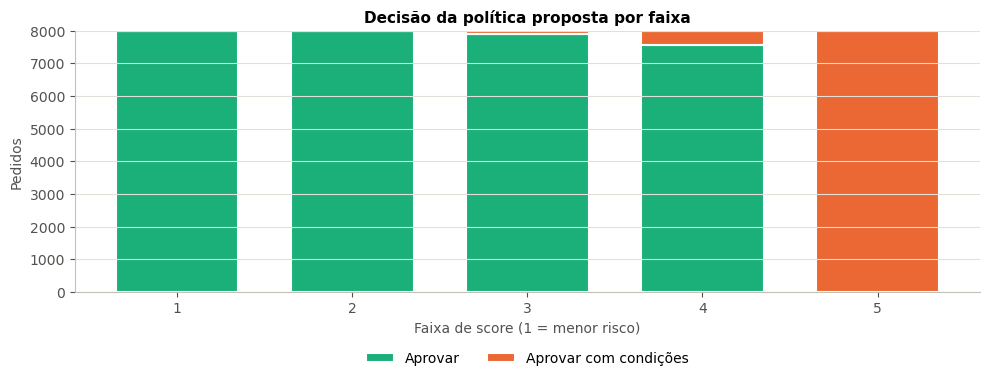

In [12]:
decidida = proposta.aplicar(carteira, TAXA_ATUAL)
decidida["decisao"] = np.select(
    [~decidida["aprovado"], (decidida["fator_credito"] < 1) | (decidida["taxa"] > TAXA_ATUAL)],
    ["Recusar", "Aprovar com condições"], default="Aprovar",
)
resumo = decidida.groupby("decisao").agg(
    pedidos=("id_cliente", "size"),
    credito_pedido=("valor_credito", lambda x: x.sum() / MILHOES),
    pd_modelo_pct=("pd_modelo", lambda x: x.mean() * 100),
    sem_historico=("hist_sem_historico", "sum"),
)
resumo["pedidos_%"] = resumo["pedidos"] / len(decidida) * 100
display(resumo.round(2))

saida = decidida[["id_cliente", "faixa", "pd_modelo", "decisao", "taxa", "fator_credito"]].rename(
    columns={"pd_modelo": "probabilidade_inadimplencia", "taxa": "taxa_mensal", "fator_credito": "fracao_do_valor_aprovada"})
saida.to_csv(PASTA_SAIDA / "politica_submissao.csv", index=False)
print(f"Decisão de cada pedido salva em outputs/politica_submissao.csv ({len(saida):,} linhas)")

fig, ax = plt.subplots(figsize=(10, 4))
contagem = decidida.groupby(["faixa", "decisao"]).size().unstack(fill_value=0)
base = np.zeros(len(contagem))
for coluna, cor in zip(["Aprovar", "Aprovar com condições", "Recusar"], [AQUA, LARANJA, CINZA]):
    if coluna in contagem:
        ax.bar(contagem.index, contagem[coluna], bottom=base, color=cor, label=coluna, width=0.7, edgecolor="white", linewidth=1.5)
        base += contagem[coluna].to_numpy()
ax.set_xticks(range(1, N_FAIXAS + 1))
ax.set(xlabel="Faixa de score (1 = menor risco)", ylabel="Pedidos", title="Decisão da política proposta por faixa")
ax.legend(frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

**Leitura.**

- **Faixas 1 a 4: aprovar** nas condições atuais. Elas pagam o retorno mínimo até no estresse.
- **Faixa 5: aprovar com condições.** Ela paga no cenário de mercado (85%), mas não no de estresse (−3%).
  - Taxa de **2,74% ao mês** (+0,2 ponto), acima dos 2,71% que o estresse exige.
  - Limite de 70% do valor pedido.
- **Sem histórico: limite de 70%**, em qualquer faixa.
- **Nenhuma recusa.**

Na carteira da submissão, isso dá **31.446 pedidos (78,6%) aprovados sem alteração** e **8.554 (21,4%) aprovados com condições**: os 8.000 da faixa 5 e mais 554 clientes sem histórico de outras faixas. Dos 2.048 clientes sem histórico, 1.494 já estão na faixa 5.

**Comparação com as alternativas** (lucro econômico, em relação à política atual):

| Política | Cenário de mercado | Cenário de estresse |
|---|---|---|
| Recusar a faixa 5 | −178 milhões; o RAROC sobe de 144,5% para 157% | +62 milhões |
| Só o ajuste de taxa na faixa 5 | +80 milhões | +76 milhões |
| Proposta completa (taxa + limites) | −7 milhões (−0,3%) | +67 milhões (+4,7%) |

- **Recusar a faixa 5 sobe o RAROC e reduz o lucro econômico** no cenário de mercado. No estresse ela ganha 62 milhões, menos do que o ajuste de taxa entrega sem recusar ninguém.
- **O ajuste de taxa se paga sozinho** e é a parte da proposta que o RAROC justifica.
- **Os limites custam ~87 milhões** de lucro econômico no cenário de mercado e reduzem o crédito concedido em 5,6%. Eles não melhoram o retorno: são uma proteção para os dois grupos em que a estimativa de risco é menos confiável. Se o banco priorizar retorno, a versão "só o ajuste de taxa" é a melhor.
- **A proposta completa fica quase neutra no cenário de mercado** e ganha no de estresse.

A decisão de cada pedido está em `outputs/politica_submissao.csv`.

## 10. Limitações

- **O resultado depende de premissas.** O nível de default (5% e 10%) e o LGD não vêm dos dados. Antes de aplicar, é preciso trocá-los pela perda real do banco, que inclui os clientes que não voltaram.
- **A margem estimada é larga, e é ela que sustenta "aprovar todos".** Se a taxa real dos pedidos for menor que os 2,54% assumidos (os 17% no teto de prazo sugerem isso para parte deles), a folga diminui e o risco passa a pesar mais.
- **Prazo e taxa da submissão são deduzidos**, porque a base só traz crédito e parcela.
- **Cinco faixas são largas.** Dentro da faixa 5, a metade de maior risco rende menos que a média da faixa, e o ajuste de +0,2 ponto não é suficiente para ela no cenário de estresse. Separar esse grupo exige mais maus observados para a estimativa ser confiável.
- **O ajuste de taxa é sensível à calibração da PD.** A PD é calibrada com 99 maus, e a regra arredonda o ajuste em passos de 0,1 ponto. Uma recalibração pode mover o ajuste da faixa 5 em um passo.
- **O prazo não foi usado como alavanca.** Reduzir o prazo eleva a parcela, o que pode aumentar o atraso, e a base não permite medir esse efeito.
- **A PD não muda quando as condições mudam.** Na prática, taxa maior pode afastar os melhores clientes e atrair os piores (seleção adversa), e parcela maior pode elevar o atraso. Não há variação de preço na base para medir isso.
- **O RAROC é do primeiro ano e antes de impostos.** Não há custo fixo por contrato, e os limites rotativos (8,5% dos pedidos) foram tratados como parcelados.
- **O modelo foi treinado só com contratos aprovados** de clientes recorrentes (viés de seleção, discutido na EDA).

**Próximos passos:**

1. Substituir as premissas pelos números do banco: perda histórica completa, custo de captação, custo operacional e retorno mínimo.
2. Testar o preço por risco em um piloto controlado, para medir como a demanda e a inadimplência respondem à taxa.
3. Calcular o RAROC de vida inteira do contrato, com um modelo de sobrevivência (trabalho futuro do notebook de modelagem).
4. Monitorar por safra a taxa de default de cada faixa e recalibrar os cenários.